In [1]:
import astropy
import expecto

from astroquery.simbad import Simbad
import astropy.units as u
from expecto import get_spectrum

print(astropy.__version__)
print(expecto.__version__)

import scienceplots
import matplotlib.pyplot as plt

# matplotlib parameters
plt.style.use(["science", "bright", "no-latex"])

plt.rcParams["image.cmap"] = "inferno"
plt.rcParams["font.family"] = "serif"
plt.rcParams["image.origin"] = "lower"
plt.rcParams["figure.dpi"] = 250
plt.rcParams["font.size"] = 8
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"

8.0.1
0.1.4


In [2]:
doc_width = 433.62  # pt
doc_width /= 72.27  # inches
print(doc_width)

spectra = {}

6.0


## HD 41094

To get a spectral slope estimate for HD 41094, we will firstly need astrophysical parameters from Gaia DR3. Let's find the Gaia DR3 identifier for HD 41094.

In [3]:
Simbad.server = "simbad.harvard.edu"  # because the SIMBAD servers are down
Simbad.add_votable_fields("ids")
result = Simbad.query_object("HD 41094")
# look through the IDS field for the "Gaia DR3 ..." identifier
print(result[0]["ids"])

TIC 149931517|Gaia DR3 4756415013173305472|2MASS J05582116-6409415|2MASSI J0558211-640941|CD-64   201|CPC 20.1  1382|CPD-64   503|GSC 08900-00244|HD  41094|MSX LMC 1668|PPM 355101|SAO 249405|TYC 8900-244-1|WISEA J055821.17-640940.2|Gaia DR1 4756415008869528832|Gaia DR2 4756415013173305472


HD 41094 A.K.A "Gaia DR3 4756415013173305472"!

Now let's query Gaia for its effective temperature, log g, and metallicity.

In [4]:
# from astroquery.gaia import Gaia

# source_id = 4756415013173305472

# query = f"""
# SELECT source_id, teff_gspphot, logg_gspphot, mh_gspphot
# FROM gaiadr3.astrophysical_parameters
# WHERE source_id = {source_id}
# """

# job = Gaia.launch_job(query)
# result = job.get_results()
# print(result)

Passing these parameters to `expecto.get_spectrum`.

In [5]:
HD41094_KWARGS = {
    "T_eff": 4830,  # K
    "log_g": 2.55,  # log(cm.s**-2)
    "Z": -0.418,  # dex
}

spec = get_spectrum(**HD41094_KWARGS, cache=True)

flux_photon = spec.flux.to(
    u.photon / u.s / u.cm**2 / u.AA,
    equivalencies=u.spectral_density(spec.spectral_axis),
)

spectra["HD 41094"] = spec, flux_photon

        Use Spectrum instead. [expecto.core]


I'll plot all the spectra together at the end. Let's get the next ones.

# EZ Aquarii

This is a tertiary system with two resolvable components. A + C is the brighter component. We want then two spectral slopes (one for each component), where one of them is the combined spectra of A and C.

Gaia does not provide reliable astrophysical parameters for the individual components, so we derive them from empirical M-dwarf relations calibrated by [Mann et al. (2015)](https://doi.org/10.1088/0004-637X/804/1/64):

1. **Absolute magnitude:** convert each component's apparent $K_s$ magnitude to an absolute magnitude using the system parallax ($\varpi = 0.2936''$): $M_{K_s} = K_s - 5\log_{10}(d/10\,\mathrm{pc})$.
2. **Radius:** apply the Mann et al. (2015) $M_{K_s}$–radius relation, $R/R_\odot = a + bM_{K_s} + cM_{K_s}^2$ (metallicity-independent form).
3. **Effective temperature:** invert the Mann et al. (2015) $T_\mathrm{eff}$–radius relation, $R/R_\odot = a + bX + cX^2 + dX^3$ with $X = T_\mathrm{eff}/3500\,\mathrm{K}$. The cubic can have several real roots, so we keep the one inside a physically plausible temperature range for each component.
4. **Surface gravity:** combine the radius with the component mass: $\log g = \log g_\odot + \log_{10}(M/M_\odot) - 2\log_{10}(R/R_\odot)$, with $\log g_\odot = 4.438$.

The resulting $T_\mathrm{eff}$ and $\log g$ for each component are passed to `expecto.get_spectrum` (at solar metallicity). PHOENIX spectra give the flux at the stellar surface, so each component's spectrum is scaled by $(R/R_\odot)^2$ (the flux received scales as $R^2/d^2$, and all components share the same distance). The scaled photon-flux spectra of A and C are then summed to model the blended A + C component.


In [6]:
from jax import numpy as np
import numpy as onp


def MKs_to_rad(MKs):
    """
    Mann et al. (2015) absolute Ks magnitude -> radius relation
    (metallicity-independent form).

    R / R_sun = a + b * MKs + c * MKs**2
    """
    X = MKs
    a = 1.9515
    b = -0.3520
    c = 0.01680

    return a + b * X + c * X**2


def MKs_to_rad2(MKs, fe_H):
    """
    Mann et al. (2015) MKs -> radius relation with a [Fe/H] correction term.

    R / R_sun = (a + b * MKs + c * MKs**2) * (1 + f * [Fe/H])

    Not used below: we have no metallicities for the EZ Aqr components.
    """
    X = MKs
    a = 1.9305
    b = -0.3466
    c = 0.01647
    f = 0.04458

    return (a + b * X + c * X**2) * (1 + f * fe_H)


def Ks_to_MKs(
    Ks,
    d_pc=1 / 0.2936,  # distance in pc, from a parallax of 0.2936 arcsec
):
    """
    Convert apparent Ks magnitude to absolute Ks magnitude (MKs)
    via the distance modulus.
    """
    return Ks - 5 * np.log10(d_pc / 10)


def R_to_Teff(
    Y,
    Trange=(2500, 3500),
    a=10.5440,
    b=-33.7546,
    c=35.1909,
    d=-11.5928,
):
    """
    Invert the Mann et al. (2015) Teff -> radius relation to get Teff from a radius.

    The relation is R / R_sun = a + b*X + c*X**2 + d*X**3, with X = Teff / 3500 K,
    so we solve the cubic d*X**3 + c*X**2 + b*X + (a - R) = 0 for X.

    Y      : radius in solar radii
    Trange : (Tmin, Tmax) in K, a prior used to choose between multiple real roots
    """
    Tmin, Tmax = Trange

    # Polynomial coefficients, highest power first (as onp.roots expects)
    coeffs = [d, c, b, a - Y]

    # Solve the cubic and keep only the real roots
    roots = onp.roots(coeffs)
    real_roots = roots[onp.isclose(roots.imag, 0)].real

    # Convert X = Teff / 3500 back to Teff in K
    Teffs = real_roots * 3500

    # Apply astrophysical prior: discard roots outside the plausible Teff range
    Teffs = Teffs[(Teffs >= Tmin) & (Teffs <= Tmax)]

    # If more than one root survives the prior, take the hotter one
    if len(Teffs) != 1:
        print(
            f"WARNING: Ambiguous Teff for R={Y}: candidates={Teffs}. Choosing the hotter option {np.max(Teffs)}."
        )

    return np.max(Teffs)


def MR_to_logg(M, R):
    """
    Surface gravity from mass and radius, scaled from the Sun:
    log g = log g_sun + log10(M / M_sun) - 2 * log10(R / R_sun),
    with log g_sun = 4.438 (cgs).
    """
    return 4.438 + np.log10(M) - 2 * np.log10(R)

In [7]:
# applies a function leaf-wise over the per-component dicts
from jax.tree import map as tree_map

# Input values for each component (from Mann et al. 2015, 2019)
masses = {"A": 0.1187, "B": 0.1145, "C": 0.0930}  # solar masses
print(f"masses: {masses}")
Kss = {"A": 6.557, "B": 6.593, "C": 7.127}  # apparent Ks magnitudes
print(f"Kss: {Kss}")

# Step 1: apparent -> absolute Ks magnitude
MKss = tree_map(Ks_to_MKs, Kss)
print(f"MKs: {MKss}")

# Step 2: absolute Ks magnitude -> radius (solar radii)
Rs = tree_map(MKs_to_rad, MKss)
print(f"Rs: {Rs}")

# Step 3: radius -> Teff (K), using a per-component Teff prior to pick the root
Teff_ranges = {"A": (2800, 3300), "B": (2800, 3300), "C": (2500, 2900)}  # K
Teffs = tree_map(R_to_Teff, Rs, Teff_ranges)
print(f"Teffs: {Teffs}")

# Step 4: mass + radius -> log g (cgs)
loggs = tree_map(MR_to_logg, masses, Rs)
print(f"loggs: {loggs}")

masses: {'A': 0.1187, 'B': 0.1145, 'C': 0.093}
Kss: {'A': 6.557, 'B': 6.593, 'C': 7.127}
MKs: {'A': Array(8.895781, dtype=float32), 'B': Array(8.93178, dtype=float32), 'C': Array(9.46578, dtype=float32)}
Rs: {'A': Array(0.14965177, dtype=float32), 'B': Array(0.14776206, dtype=float32), 'C': Array(0.12484205, dtype=float32)}
Teffs: {'A': Array(2939.6428, dtype=float32), 'B': Array(2931.4922, dtype=float32), 'C': Array(2765.921, dtype=float32)}
loggs: {'A': Array(5.162287, dtype=float32), 'B': Array(5.15768, dtype=float32), 'C': Array(5.2137613, dtype=float32)}


In [8]:
def get_photon_flux(component):
    """
    Get the PHOENIX spectrum for one EZ Aqr component, in photon units, scaled by (R / R_sun)^2.

    PHOENIX fluxes are at the stellar surface. The flux we receive scales as (R / d)^2,
    and all components share the same distance, so weighting by R^2 puts them on a
    common relative scale before they are summed.
    """
    spec = get_spectrum(
        T_eff=float(Teffs[component]), log_g=float(loggs[component]), cache=True
    )
    flux_photon = float(Rs[component]) ** 2 * spec.flux.to(
        u.photon / u.s / u.cm**2 / u.AA,
        equivalencies=u.spectral_density(spec.spectral_axis),
    )
    return spec, flux_photon


A_spec, A_flux_photon = get_photon_flux("A")
B_spec, B_flux_photon = get_photon_flux("B")
C_spec, C_flux_photon = get_photon_flux("C")

# A and C are unresolved, so we model their combined (R^2-weighted) spectrum
spectra["EZ Aqr A+C"] = A_spec, A_flux_photon + C_flux_photon
spectra["EZ Aqr B"] = B_spec, B_flux_photon

        Use Spectrum instead. [expecto.core]
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead. [expecto.core]


# Spectral slopes

Now that we have a photon-flux spectrum for each target, we compute its slope across each of the F380M, F430M and F480M filters. For each filter we:

1. split the filter's wavelength range into 9 equal-width bins (the same binning `amigo` uses) and integrate the photon flux over each bin;
2. normalise the bin weights to a mean of 1;
3. fit a straight line to the weights, with the band mapped onto $x \in [-1, 1]$.

The gradient of that line is the spectral slope. The filter throughput curves are copied from `amigo` into `files/filters/`, and are only plotted for reference: the weights are the stellar spectrum alone, not multiplied by the throughput.

In [9]:
FILTERS = {"F380M": "tab:blue", "F430M": "tab:green", "F480M": "tab:red"}
NWAVELS = 9  # number of wavelength bins per filter


def load_filter(filt):
    """Filter throughput curve (copied from amigo): wavelength (Angstrom), throughput."""
    return onp.loadtxt(f"files/filters/{filt}.dat", unpack=True)


def bin_in_filter(filt, wl, y, nwavels=NWAVELS):
    """
    Split the filter's wavelength range into `nwavels` equal-width bins and
    integrate `y` (sampled at wavelengths `wl`, in Angstrom) over each bin.

    Returns the bin centres (Angstrom) and the bin integrals normalised to a mean of 1.
    """
    filt_wl, _ = load_filter(filt)
    edges = onp.linspace(filt_wl.min(), filt_wl.max(), nwavels + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])
    areas = onp.array(
        [
            onp.trapezoid(onp.where((lo < wl) & (wl < hi), y, 0), wl)
            for lo, hi in zip(edges[:-1], edges[1:])
        ]
    )
    return centres, areas / areas.mean()

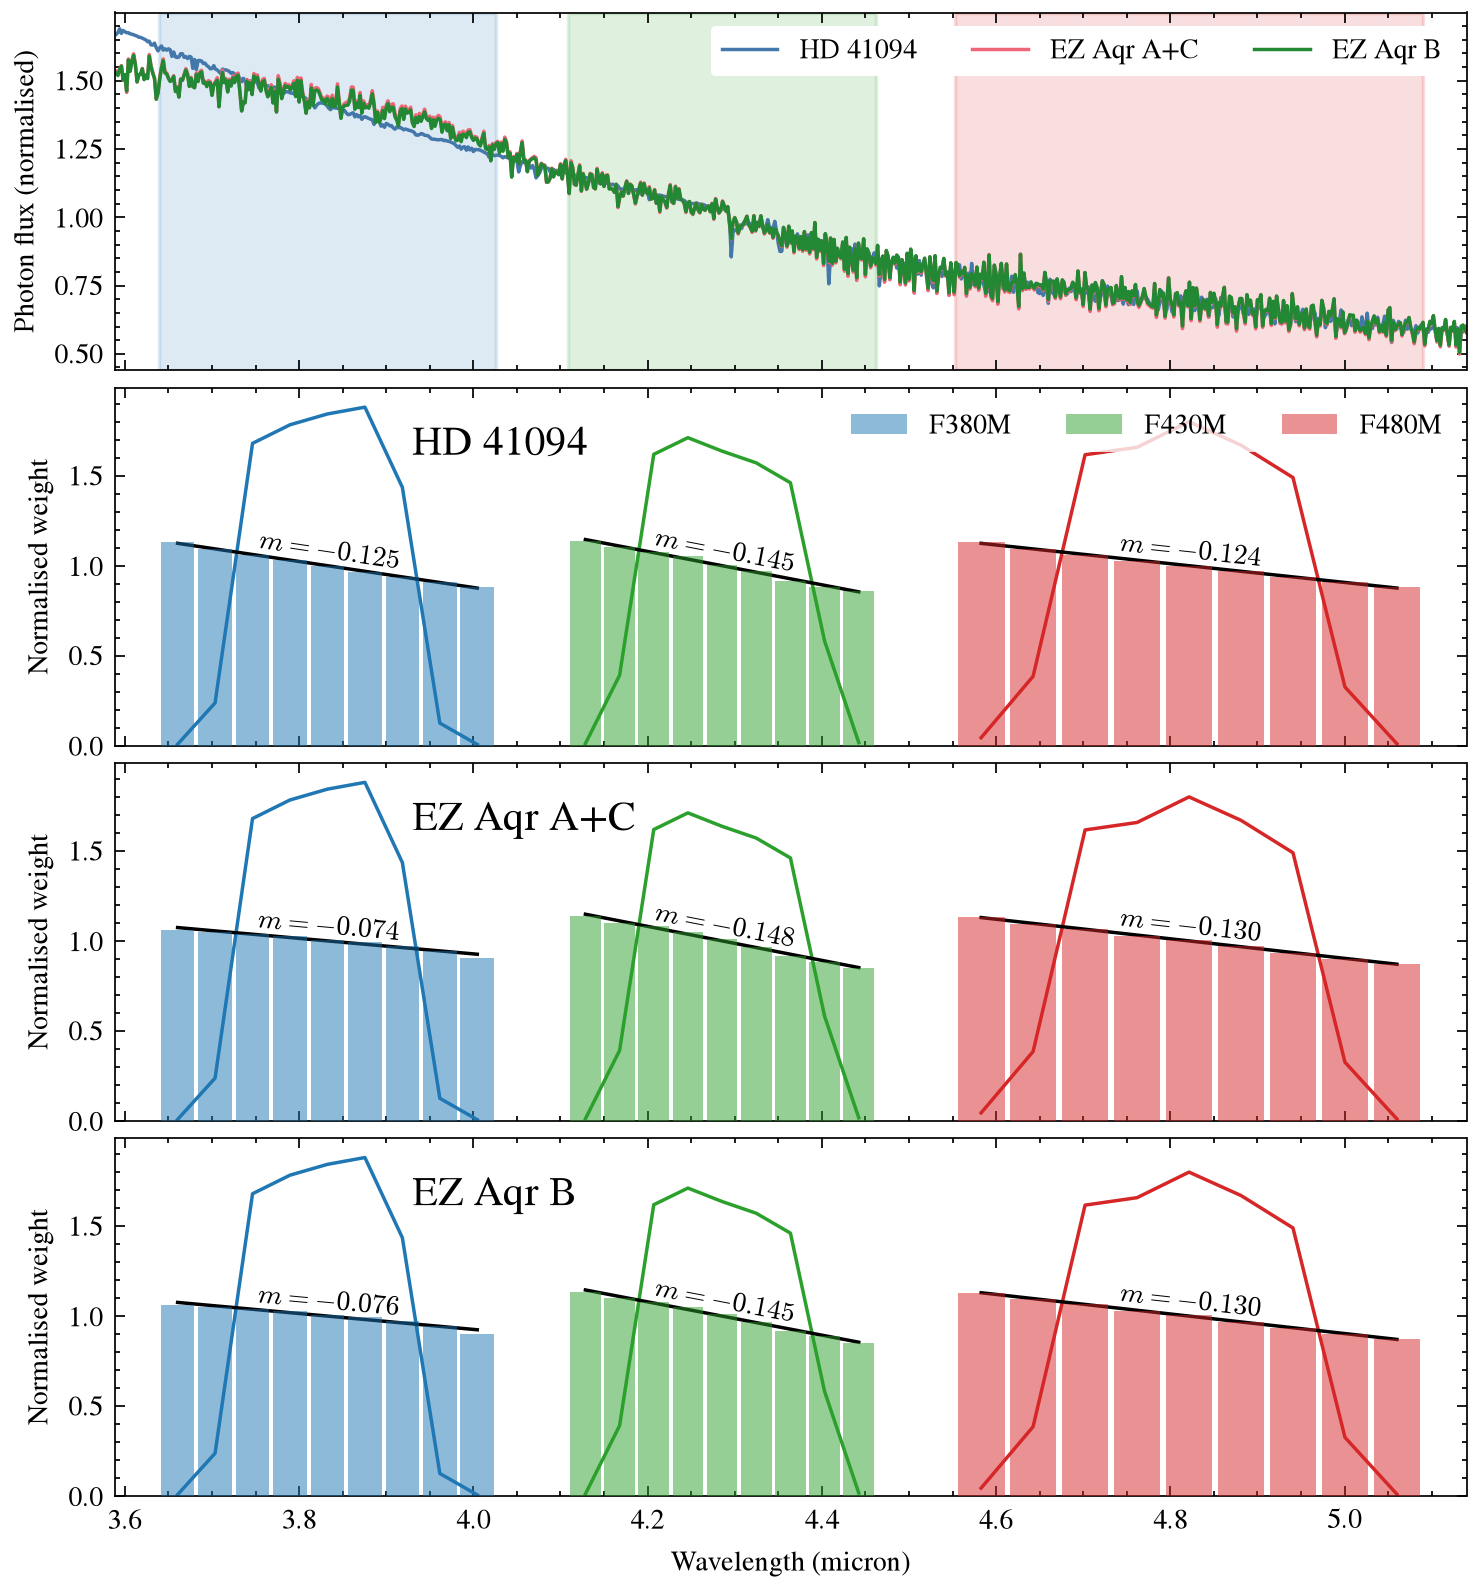

                 F380M     F430M     F480M
HD 41094       -0.1245   -0.1455   -0.1244
EZ Aqr A+C     -0.0742   -0.1484   -0.1297
EZ Aqr B       -0.0761   -0.1453   -0.1298


In [23]:
slopes = {}

# Top row: all spectra together. Below: one row per target with its binned weights.
# All rows share the wavelength axis; only the weight rows share a y-axis.
fig, axes = plt.subplots(len(spectra) + 1, 1, figsize=(doc_width, 6.5), sharex=True)
spec_ax, slope_axes = axes[0], axes[1:]
for ax in slope_axes[1:]:
    ax.sharey(slope_axes[0])

# Wavelength range covered by the filters (micron), with a small margin
filt_wls = [load_filter(filt)[0] for filt in FILTERS]
xlim = (
    min(w.min() for w in filt_wls) / 1e4 - 0.05,
    max(w.max() for w in filt_wls) / 1e4 + 0.05,
)

# --- Top row: spectra ---
# The PHOENIX spectra are very high resolution, so for display we average them into
# 20 Angstrom bins, and normalise each over the plotted range so they share an axis.
plot_edges = onp.arange(xlim[0] * 1e4, xlim[1] * 1e4 + 20, 20)
plot_centres = 0.5 * (plot_edges[:-1] + plot_edges[1:])

for name, (spec, flux) in spectra.items():
    wl = spec.spectral_axis.to(u.AA).value
    summed, _ = onp.histogram(wl, bins=plot_edges, weights=flux.value)
    counts, _ = onp.histogram(wl, bins=plot_edges)
    binned = summed / counts
    spec_ax.plot(plot_centres / 1e4, binned / binned.mean(), linewidth=1, label=name)

# Shade each filter's wavelength range
for filt, colour in FILTERS.items():
    filt_wl, _ = load_filter(filt)
    spec_ax.axvspan(filt_wl.min() / 1e4, filt_wl.max() / 1e4, color=colour, alpha=0.15)

spec_ax.set_ylabel("Photon flux (normalised)")
spec_legend = spec_ax.legend(
    loc="upper right", ncol=3, frameon=True, framealpha=1, edgecolor="none"
)
spec_legend.set_zorder(20)

# --- Remaining rows: binned weights and slopes for each target ---
for ax, (name, (spec, flux)) in zip(slope_axes, spectra.items()):
    wl = spec.spectral_axis.to(u.AA).value
    slopes[name] = {}

    for filt, colour in FILTERS.items():
        # Photon-flux weights in each bin
        centres, weights = bin_in_filter(filt, wl, flux.value)
        centres_um = centres / 1e4  # Angstrom -> micron, for plotting
        ax.bar(
            centres_um,
            weights,
            width=0.9 * onp.diff(centres_um).mean(),
            color=colour,
            alpha=0.5,
            label=filt,
            zorder=10,
        )

        # Filter throughput binned the same way, for reference
        filt_wl, filt_tp = load_filter(filt)
        _, tp_weights = bin_in_filter(filt, filt_wl, filt_tp)
        ax.plot(centres_um, tp_weights, color=colour)

        # Straight-line fit across the band, with the band mapped onto x in [-1, 1]
        xs = onp.linspace(-1, 1, len(centres))
        m, b = onp.polyfit(xs, weights, 1)
        ax.plot(centres_um, m * xs + b, color="black")
        slopes[name][filt] = m

        # Label the fit with its gradient, sitting on the line like an underline.
        # The angle is given in data coordinates (x in [-1, 1] spans the band), and
        # transform_rotates_text converts it to the on-screen angle at draw time.
        data_gradient = 2 * m / (centres_um[-1] - centres_um[0])  # per micron
        ax.text(
            centres_um.mean(),
            b,  # fit value at the band centre (x = 0)
            f"$m = {m:.3f}$",
            ha="center",
            va="bottom",
            rotation=onp.degrees(onp.arctan(data_gradient)),
            rotation_mode="anchor",
            transform_rotates_text=True,
            zorder=20,
        )

    # Target name inside the panel (top left) instead of a title,
    # on an opaque background drawn above the data
    ax.text(
        0.22,
        0.9,
        name,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=12,
        # bbox=dict(facecolor="white", edgecolor="none"),
        zorder=20,
    )
    ax.set_ylabel("Normalised weight")
    # ax.axhline(1.0, linestyle="--", color="k", alpha=0.5, zorder=-10)

slope_axes[0].set_ylim(0, 1.99)  # headroom above the throughput curves for the labels

# Opaque legend, drawn above the data
legend = slope_axes[0].legend(
    loc="upper right", ncol=3, frameon=True, framealpha=0.8, edgecolor="none"
)
legend.set_zorder(20)

axes[-1].set_xlim(xlim)
axes[-1].set_xlabel("Wavelength (micron)")
fig.tight_layout(h_pad=0)
plt.savefig("files/retrain_figs/spectra.pdf", bbox_inches="tight", dpi=300)
plt.savefig("files/retrain_figs/spectra.png", bbox_inches="tight", dpi=300)
plt.show()

# Summary table of slopes
print(f"{'':<12}" + "".join(f"{filt:>10}" for filt in FILTERS))
for name, s in slopes.items():
    print(f"{name:<12}" + "".join(f"{s[filt]:10.4f}" for filt in FILTERS))